# EDA — Deserción en educación superior (Colombia), IES × año

Análisis exploratorio del dataset que produce `pipeline.py` (`data/processed/dataset_ies.csv`).
Cada fila es una IES en un año (2015–2021); la variable objetivo es `tasa_desercion` (SPADIES, MEN) y las
explicativas llegan rezagadas (Saber 11 y TerriData en t-1; matrícula SNIES en t-2). El contexto territorial se
une por el municipio sede de la IES.

**Alcance.** Se describen asociaciones, no causas, y el nivel de análisis es la institución, no el estudiante.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto y librerías
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Polygon
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.homologation.divipola import cargar_divipola
from src.validate.dictionary import describir_columnas

# Paleta del proyecto: azul = oficial, naranja = privada; rampa azul para magnitudes
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
RAMPA = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

## 1. Carga y descripción general

In [2]:
cfg = load_config(ROOT / "config" / "config.yaml")
assert cfg["unidad_analisis"] == "ies", "este EDA es para la unidad IES x año"
ruta = ROOT / cfg["rutas"]["processed"] / "dataset_ies.csv"

# Los códigos son texto para conservar los ceros a la izquierda (p. ej. 05001)
df = pd.read_csv(ruta, dtype={"cod_ies": str, "cod_divipola_mpio": str, "sector": str, "caracter": str})
divipola = cargar_divipola(ROOT / cfg["rutas"]["raw"] / "dane" / "divipola.csv")
deptos = divipola.drop_duplicates("cod_depto").set_index("cod_depto")["depto_norm"].str.title()

df["cod_depto"] = df["cod_divipola_mpio"].str[:2]
df["departamento"] = df["cod_depto"].map(deptos)
df["naturaleza"] = df["sector"].map({"1": "Oficial", "2": "Privada"})  # id_sector de SNIES
assert df["tasa_desercion"].notna().all(), "tasa_desercion tiene nulos: falta el export de SPADIES"

print(f"{len(df):,} filas · {df['cod_ies'].nunique()} IES · años {df['anio'].min()}–{df['anio'].max()} · {df.shape[1]} columnas")
print("IES por naturaleza:", df.drop_duplicates("cod_ies")["naturaleza"].value_counts().to_dict())

2,042 filas · 311 IES · años 2015–2021 · 41 columnas
IES por naturaleza: {'Privada': 217, 'Oficial': 94}


In [3]:
# Control de la codificación de naturaleza contra el catálogo oficial de IES (sector Oficial/Privado)
catalogo = ROOT / cfg["rutas"]["raw"] / "snies" / "ies_catalogo.csv"
if catalogo.exists():
    cat = pd.read_csv(catalogo, dtype=str).rename(columns={"c_digo_instituci_n": "cod_ies", "sector": "sector_catalogo"})
    cruce = df.drop_duplicates("cod_ies").merge(cat[["cod_ies", "sector_catalogo"]], on="cod_ies", how="left")
    display(pd.crosstab(cruce["naturaleza"], cruce["sector_catalogo"].fillna("sin catálogo")))

sector_catalogo,Oficial,Privado,sin catálogo
naturaleza,,,
Oficial,93,0,1
Privada,1,216,0


In [4]:
# Tipos de dato y resumen de las variables numéricas
display(df.dtypes.to_frame("tipo").T)
display(df.describe().T.round(3))

,cod_ies,anio,tasa_desercion,posible_cierre,cod_divipola_mpio,sector,caracter,matriculados_ies_t2,punt_global_media_t1,punt_global_mediana_t1,pct_estrato_bajo_t1,pct_colegio_oficial_t1,n_estudiantes_t1,mpio_matriculados_t2,mpio_ies_con_oferta_t2,td_cob_bruta_media_t1,td_cob_bruta_total_t1,td_cob_neta_media_t1,td_desercion_escolar_t1,td_idf_t1,...,td_idf_deuda_t1,td_idf_inversion_t1,td_idf_recursos_propios_t1,td_idf_transferencias_t1,td_ipm_censo_t1,td_mdm_t1,td_mdm_educacion_t1,td_mdm_gestion_t1,td_mdm_resultados_t1,td_miseria_pct_t1,td_nbi_pct_t1,td_pct_pob_15_19_t1,td_pct_pob_20_24_t1,td_pct_poblacion_rural_t1,td_repitencia_oficial_t1,td_transito_superior_t1,td_poblacion_total_t1,cod_depto,departamento,naturaleza
tipo,str,int64,float64,bool,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str,str,str


,count,mean,std,min,25%,50%,75%,max
anio,2042.0,2017.993,1.995,2015.000,2016.000,2018.000,2020.000,2021.000
tasa_desercion,2042.0,0.122,0.093,0.003,0.072,0.098,0.141,0.994
matriculados_ies_t2,1440.0,8247.940,27695.008,37.000,957.750,3577.500,8724.000,467643.000
punt_global_media_t1,1462.0,262.678,12.946,206.894,254.395,264.055,270.213,294.815
punt_global_mediana_t1,1462.0,260.127,14.319,201.000,250.000,263.000,267.375,295.000
pct_estrato_bajo_t1,1462.0,0.634,0.131,0.244,0.552,0.579,0.732,1.000
pct_colegio_oficial_t1,1462.0,0.626,0.121,0.347,0.529,0.620,0.696,1.000
n_estudiantes_t1,1462.0,36616.512,38416.262,74.000,4397.500,17316.000,90956.000,96708.000
mpio_matriculados_t2,2038.0,294206.910,319522.895,54.000,33049.000,126166.000,708245.000,804455.000
mpio_ies_con_oferta_t2,2038.0,56.763,47.628,1.000,16.000,37.000,122.000,126.000


## 2. Distribución de la tasa de deserción

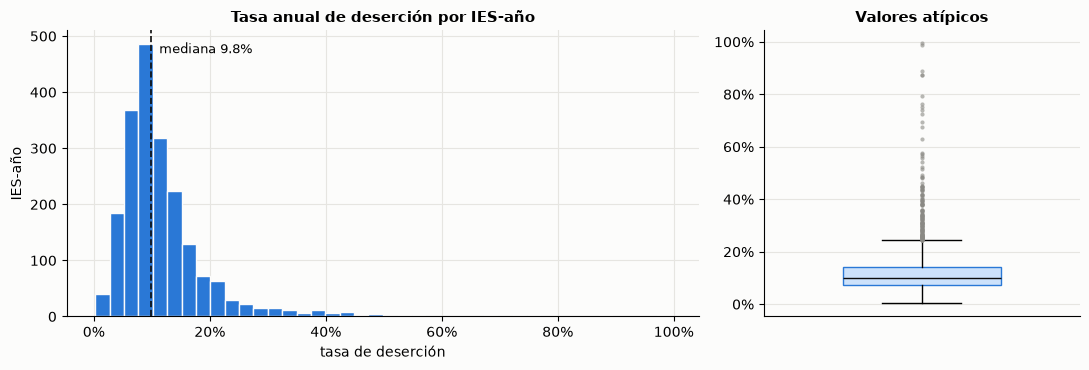

,0.05,0.25,0.50,0.75,0.95
tasa_desercion,0.04,0.072,0.098,0.141,0.275


Asimetría: 3.79 · IES-año con tasa > 50 %: 20


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].hist(df["tasa_desercion"], bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=1)
mediana = df["tasa_desercion"].median()
ejes[0].axvline(mediana, color="#0b0b0b", lw=1.2, ls="--")
ejes[0].annotate(f"mediana {mediana:.1%}", (mediana, ejes[0].get_ylim()[1] * 0.92), xytext=(6, 0),
                 textcoords="offset points", fontsize=9)
ejes[0].set(title="Tasa anual de deserción por IES-año", xlabel="tasa de deserción", ylabel="IES-año")
ejes[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

ejes[1].boxplot(df["tasa_desercion"], orientation="vertical", widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
ejes[1].set(title="Valores atípicos", xticks=[])
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

q = df["tasa_desercion"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3)
display(q.to_frame("tasa_desercion").T)
print(f"Asimetría: {stats.skew(df['tasa_desercion']):.2f} · IES-año con tasa > 50 %: {(df['tasa_desercion'] > 0.5).sum()}")

In [6]:
# Las tasas muy altas suelen venir de IES pequeñas o de crecimiento rápido (el denominador es la matrícula de hace un año)
altas = df[df["tasa_desercion"] > 0.5].copy()
display(altas[["cod_ies", "anio", "departamento", "naturaleza", "tasa_desercion", "matriculados_ies_t2"]]
        .sort_values("tasa_desercion", ascending=False).head(10).round(3))
print("Matrícula t-2 mediana de las IES-año con tasa > 50 %:", altas["matriculados_ies_t2"].median(),
      "· del resto:", df.loc[df["tasa_desercion"] <= 0.5, "matriculados_ies_t2"].median())

,cod_ies,anio,departamento,naturaleza,tasa_desercion,matriculados_ies_t2
1984,9903,2019,"Bogota, D.C.",Privada,0.994,146.0
1985,9903,2020,"Bogota, D.C.",Privada,0.987,184.0
1360,3114,2018,Atlantico,Oficial,0.889,130.0
1981,9903,2016,"Bogota, D.C.",Privada,0.873,NaN
786,2106,2016,"Bogota, D.C.",Oficial,0.873,NaN
1983,9903,2018,"Bogota, D.C.",Privada,0.792,278.0
1527,3807,2021,Antioquia,Privada,0.765,254.0
1746,4808,2021,Valle Del Cauca,Privada,0.753,374.0
1796,4826,2016,Bolivar,Privada,0.742,NaN
1965,9899,2020,"Bogota, D.C.",Privada,0.725,1971.0


Matrícula t-2 mediana de las IES-año con tasa > 50 %: 265.0 · del resto: 3620.5


### Efecto del denominador mínimo (`min_matriculados_t2`)

La tasa es desertores sobre la matrícula de dos semestres atrás; con denominadores chicos es muy inestable. El ETL excluye las
IES-año cuyo denominador (promedio de los dos semestres de t-2) es menor que `min_matriculados_t2` de `config.yaml`. Aquí se
compara el dataset sin ese filtro (mínimo = 0) con el que se usa.

Mínimo de matrícula t-2: 100
IES-año sin filtro: 2,148 · con el mínimo: 2,051 · eliminadas: 97 (4.5%) · IES que desaparecen por completo: 9
Después se excluyen 9 IES-año por posible cierre (excluir_posible_cierre = True): dataset final 2,042 filas, 311 IES


,sin filtro,con el mínimo,eliminadas por el mínimo,dataset final
filas,2148.000,2051.000,97.000,2042.000
media,0.129,0.122,0.279,0.122
mediana,0.100,0.098,0.248,0.098
desv. est.,0.106,0.093,0.202,0.093
p95,0.311,0.277,0.729,0.275
máximo,0.994,0.994,0.917,0.994
asimetría,3.510,3.767,1.200,3.792
filas con tasa > 50 %,33.000,20.000,13.000,20.000


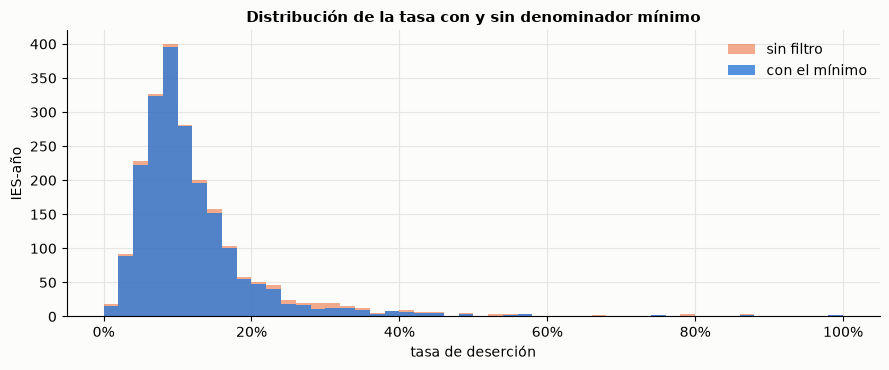

In [7]:
from src.extract.spadies import leer_spadies

minimo = cfg.get("min_matriculados_t2", 100)
# Las rutas de config.yaml son relativas a la raíz del proyecto, no a notebooks/
spadies_abs = {k: (str(ROOT / v) if k in ("archivo", "nacional") else v) for k, v in cfg["spadies"].items()}
base = {**cfg, "spadies": spadies_abs, "excluir_posible_cierre": False}  # el efecto de los posibles cierres se ve aparte
ventana = lambda t: t[t["anio"].between(min(cfg["anios"]), max(cfg["anios"]))]
sin_filtro = ventana(leer_spadies({**base, "min_matriculados_t2": 0}, []))
con_minimo = ventana(leer_spadies({**base, "min_matriculados_t2": minimo}, []))
llave = ["cod_ies", "anio"]
quitadas = sin_filtro.merge(con_minimo[llave], on=llave, how="left", indicator=True).query("_merge == 'left_only'")

print(f"Mínimo de matrícula t-2: {minimo}")
print(f"IES-año sin filtro: {len(sin_filtro):,} · con el mínimo: {len(con_minimo):,} · eliminadas: {len(quitadas):,} "
      f"({len(quitadas) / len(sin_filtro):.1%}) · IES que desaparecen por completo: "
      f"{sin_filtro['cod_ies'].nunique() - con_minimo['cod_ies'].nunique()}")
print(f"Después se excluyen {len(con_minimo) - len(df):,} IES-año por posible cierre (excluir_posible_cierre = "
      f"{cfg.get('excluir_posible_cierre', True)}): dataset final {len(df):,} filas, {df['cod_ies'].nunique()} IES")

def resumen(serie):
    return pd.Series({"filas": len(serie), "media": serie.mean(), "mediana": serie.median(), "desv. est.": serie.std(),
                      "p95": serie.quantile(0.95), "máximo": serie.max(), "asimetría": stats.skew(serie),
                      "filas con tasa > 50 %": int((serie > 0.5).sum())})

comparacion = pd.DataFrame({"sin filtro": resumen(sin_filtro["tasa_desercion"]),
                            "con el mínimo": resumen(con_minimo["tasa_desercion"]),
                            "eliminadas por el mínimo": resumen(quitadas["tasa_desercion"]),
                            "dataset final": resumen(df["tasa_desercion"])})
display(comparacion.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 51)
ax.hist(sin_filtro["tasa_desercion"], bins=bins, color=NARANJA, alpha=0.55, label="sin filtro")
ax.hist(con_minimo["tasa_desercion"], bins=bins, color=AZUL, alpha=0.8, label="con el mínimo")
ax.set(title="Distribución de la tasa con y sin denominador mínimo", xlabel="tasa de deserción", ylabel="IES-año")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### IES-año con tasa > 50 % y posible cierre

`reports/tasas_altas.csv` (lo escribe el pipeline) lista las IES-año con tasa mayor que `umbral_tasa_alta` tras el denominador
mínimo, con el denominador de SPADIES, la matrícula t-2 de SNIES y el último periodo que reportó la IES. `posible_cierre` marca
las filas que caen en los 2 semestres previos al último reporte (o en ese reporte) de una IES que dejó de reportar antes del final del archivo.

In [8]:
tasas_altas = pd.read_csv(ROOT / cfg["rutas"]["reports"] / "tasas_altas.csv", dtype={"cod_ies": str})
display(tasas_altas.round({"tasa_desercion": 3, "matriculados_t2_spadies": 0}))
print(f"{len(tasas_altas)} IES-año de {tasas_altas['cod_ies'].nunique()} IES · en ventana de posible cierre: "
      f"{int(tasas_altas['posible_cierre'].sum())} · IES con último reporte 2024-2 (siguen activas): "
      f"{(tasas_altas.drop_duplicates('cod_ies')['ultimo_periodo'] == '2024-2').sum()} de {tasas_altas['cod_ies'].nunique()}")

,cod_ies,nombre,anio,tasa_desercion,matriculados_t2_spadies,ultimo_periodo,posible_cierre,matriculados_t2_snies
0,2106,DIRECCION NACIONAL DE ESCUELAS,2016,0.873,1271.0,2024-2,False,NaN
1,2824,CORPORACION UNIVERSITARIA DE COLOMBIA IDEAS,2017,0.575,208.0,2022-2,False,905.0
2,3114,ESCUELA NAVAL DE SUBOFICIALES ARC BARRANQUILLA,2018,0.889,294.0,2024-2,False,130.0
3,3716,TECNOLOGICA FITEC,2015,0.572,752.0,2024-2,False,NaN
4,3807,ESCUELA DE TECNOLOGIAS DE ANTIOQUIA -ETA-,2021,0.765,164.0,2024-2,False,254.0
5,3828,CORPORACIÓN TECNOLÓGICA DE EDUCACIÓN SUPERIOR ...,2018,0.524,169.0,2022-2,False,115.0
6,4808,CORPORACION REGIONAL DE EDUCACION SUPERIOR-CRE...,2021,0.753,150.0,2024-2,False,374.0
7,4812,CORPORACION DE EDUCACION SUPERIOR SURAMERICA,2017,0.676,380.0,2024-2,False,276.0
8,4826,CORPORACION UNIVERSITARIA REGIONAL DEL CARIBE ...,2015,0.558,325.0,2022-2,False,NaN
9,4826,CORPORACION UNIVERSITARIA REGIONAL DEL CARIBE ...,2016,0.742,234.0,2022-2,False,NaN


20 IES-año de 13 IES · en ventana de posible cierre: 0 · IES con último reporte 2024-2 (siguen activas): 10 de 13


## 3. Evolución 2015–2021

,mediana,media,p25,p75,n
anio,,,,,
2015,0.103,0.132,0.076,0.154,291
2016,0.100,0.126,0.076,0.141,292
2017,0.111,0.132,0.079,0.150,294
2018,0.098,0.121,0.074,0.139,295
2019,0.096,0.112,0.070,0.132,292
2020,0.093,0.117,0.070,0.131,290
2021,0.090,0.111,0.062,0.138,288


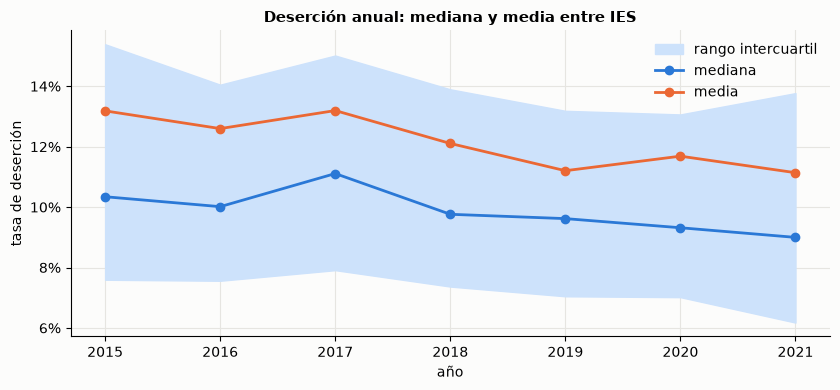

In [9]:
por_anio = df.groupby("anio")["tasa_desercion"].agg(
    mediana="median", media="mean", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75), n="size")
display(por_anio.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.fill_between(por_anio.index, por_anio["p25"], por_anio["p75"], color="#cde2fb", label="rango intercuartil")
ax.plot(por_anio.index, por_anio["mediana"], color=AZUL, lw=2, marker="o", markersize=6, label="mediana")
ax.plot(por_anio.index, por_anio["media"], color=NARANJA, lw=2, marker="o", markersize=6, label="media")
ax.set(title="Deserción anual: mediana y media entre IES", xlabel="año", ylabel="tasa de deserción")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## 4. Oficial frente a privada

,size,median,mean,std
naturaleza,,,,
Oficial,615,0.085,0.107,0.082
Privada,1427,0.103,0.128,0.097


Mann-Whitney U (oficial vs. privada): p = 1.75e-13. Las observaciones de una misma IES no son independientes, así que el valor p es solo orientativo.


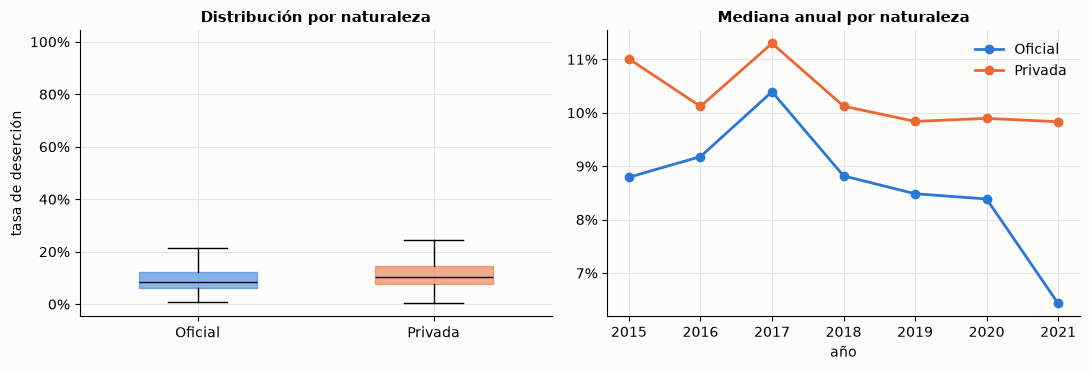

In [10]:
resumen = df.groupby("naturaleza")["tasa_desercion"].agg(["size", "median", "mean", "std"]).round(3)
display(resumen)
oficial = df.loc[df["naturaleza"] == "Oficial", "tasa_desercion"]
privada = df.loc[df["naturaleza"] == "Privada", "tasa_desercion"]
u, p = stats.mannwhitneyu(oficial, privada)
print(f"Mann-Whitney U (oficial vs. privada): p = {p:.3g}. Las observaciones de una misma IES no son independientes, "
      "así que el valor p es solo orientativo.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].boxplot([oficial, privada], tick_labels=["Oficial", "Privada"], widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markeredgecolor="none", alpha=0.5))
for caja, color in zip(ejes[0].patches, [AZUL, NARANJA]):
    caja.set(facecolor=color, alpha=0.55, edgecolor=color)
ejes[0].set(title="Distribución por naturaleza", ylabel="tasa de deserción")
ejes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

serie = df.groupby(["anio", "naturaleza"])["tasa_desercion"].median().unstack()
for nombre, color in (("Oficial", AZUL), ("Privada", NARANJA)):
    ejes[1].plot(serie.index, serie[nombre], color=color, lw=2, marker="o", markersize=6, label=nombre)
ejes[1].set(title="Mediana anual por naturaleza", xlabel="año")
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ejes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Por departamento (sede de la IES)

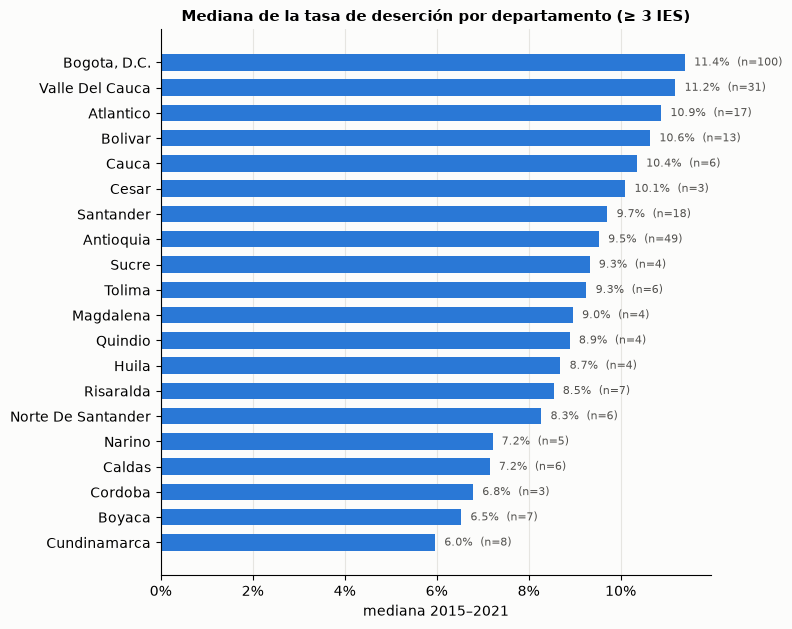

27 departamentos con IES en el dataset; 7 tienen menos de 3 y no se grafican.


In [11]:
dep = df.groupby("departamento").agg(ies=("cod_ies", "nunique"), mediana=("tasa_desercion", "median"),
                                       media=("tasa_desercion", "mean")).sort_values("mediana")
# Con pocas IES la mediana departamental es muy inestable: se grafican solo los departamentos con 3 o más
grande = dep[dep["ies"] >= 3]
fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(grande))))
ax.barh(grande.index, grande["mediana"], color=AZUL, height=0.65)
for y, (m, n) in enumerate(zip(grande["mediana"], grande["ies"])):
    ax.text(m + 0.002, y, f"{m:.1%}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set(title="Mediana de la tasa de deserción por departamento (≥ 3 IES)", xlabel="mediana 2015–2021")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"{len(dep)} departamentos con IES en el dataset; {len(dep) - len(grande)} tienen menos de 3 y no se grafican.")

## 6. Valores nulos por fuente

,% nulos promedio,% nulos máximo,variables
fuente,,,
Saber 11 (ICFES),28.4,28.4,5
SNIES (MEN),6.0,29.5,5
TerriData (DNP),5.8,28.6,23
SPADIES (MEN),0.0,0.0,1


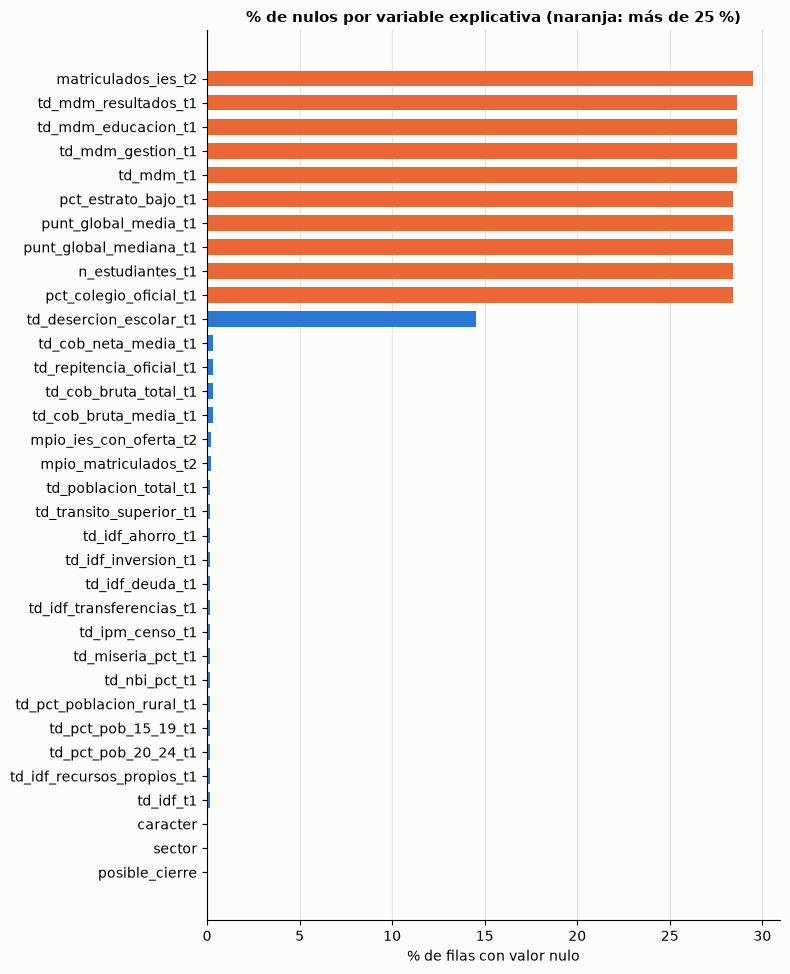

In [12]:
fuentes, _ = describir_columnas(list(df.columns))
explicativas = [c for c in df.columns if c in fuentes and c not in ("tasa_desercion", "cod_ies", "cod_divipola_mpio", "anio")]
nulos = (df[explicativas].isna().mean() * 100).rename("% nulos").to_frame()
nulos["fuente"] = [fuentes[c] for c in nulos.index]

por_fuente = nulos.groupby("fuente")["% nulos"].agg(["mean", "max", "size"]).round(1)
por_fuente.columns = ["% nulos promedio", "% nulos máximo", "variables"]
display(por_fuente.sort_values("% nulos promedio", ascending=False))

fig, ax = plt.subplots(figsize=(8, 0.26 * len(nulos) + 1))
orden = nulos.sort_values("% nulos")
ax.barh(orden.index, orden["% nulos"], color=[NARANJA if v > 25 else AZUL for v in orden["% nulos"]], height=0.65)
ax.set(title="% de nulos por variable explicativa (naranja: más de 25 %)", xlabel="% de filas con valor nulo")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [13]:
# Variables descartadas por exceso de nulos y otras observaciones de calidad de la última corrida
log = (ROOT / cfg["rutas"]["reports"] / "etl_log.md").read_text(encoding="utf-8")
for linea in log.splitlines():
    if "descartada(s) por superar" in linea or "sin municipio sede" in linea or "cobertura incompleta" in linea:
        print(linea[:400])

- **Otras limitaciones** ya documentadas: 28,5 % de nulos en Saber 11 (años con cobertura incompleta), `matriculados_ies_t2` casi coincide con el denominador de la tasa, cambio de base de las proyecciones de población entre 2017 y 2018 (ver abajo) y muchas variables territoriales colineales.
- Saber 11: cobertura incompleta en los años [2018, 2020, 2021] (falta el calendario A); se excluyen, por lo que las variables Saber 11 de los años [2019, 2021, 2022] quedan nulas
- TerriData: 5 de 28 variable(s) descartada(s) por superar 50% de nulos tras el rezago: td_cob_superior_t1 (57%), td_cotizantes_t1 (57%), td_empresas_empleo_formal_t1 (57%), td_ocupacion_formal_pct_t1 (57%), td_tgp_t1 (65%)
- TerriData: 1 de 311 IES sin municipio sede en TerriData (4106→88001); quedan con sus variables td_* nulas


**Lectura.** Los nulos de `matriculados_ies_t2` en 2015–2016 son esperados (la matrícula por programa de SNIES empieza en 2015
y el rezago es de dos años). Las de Saber 11 vienen de los años con cobertura incompleta del calendario A, que el ETL excluye
en vez de usar una muestra sesgada.

## 7. Correlaciones de las variables explicativas con la tasa

,matriculados_ies_t2,td_pct_poblacion_rural_t1,td_cob_bruta_total_t1,td_cob_bruta_media_t1,td_idf_transferencias_t1,td_idf_deuda_t1,pct_colegio_oficial_t1,td_mdm_educacion_t1,td_idf_inversion_t1,td_repitencia_oficial_t1,td_desercion_escolar_t1,pct_estrato_bajo_t1,td_pct_pob_15_19_t1,td_mdm_resultados_t1,td_idf_recursos_propios_t1,td_transito_superior_t1,td_cob_neta_media_t1,td_nbi_pct_t1,punt_global_mediana_t1,td_pct_pob_20_24_t1,td_miseria_pct_t1,punt_global_media_t1,td_ipm_censo_t1,td_mdm_t1,td_mdm_gestion_t1,td_idf_ahorro_t1,td_idf_t1,mpio_matriculados_t2,mpio_ies_con_oferta_t2,n_estudiantes_t1,td_poblacion_total_t1,privada
rho de Spearman,-0.327,-0.186,-0.143,-0.119,-0.118,-0.112,-0.104,-0.098,-0.094,-0.056,-0.048,-0.041,-0.021,-0.019,-0.018,0.004,0.008,0.012,0.016,0.016,0.024,0.028,0.033,0.06,0.066,0.083,0.102,0.106,0.123,0.128,0.14,0.163


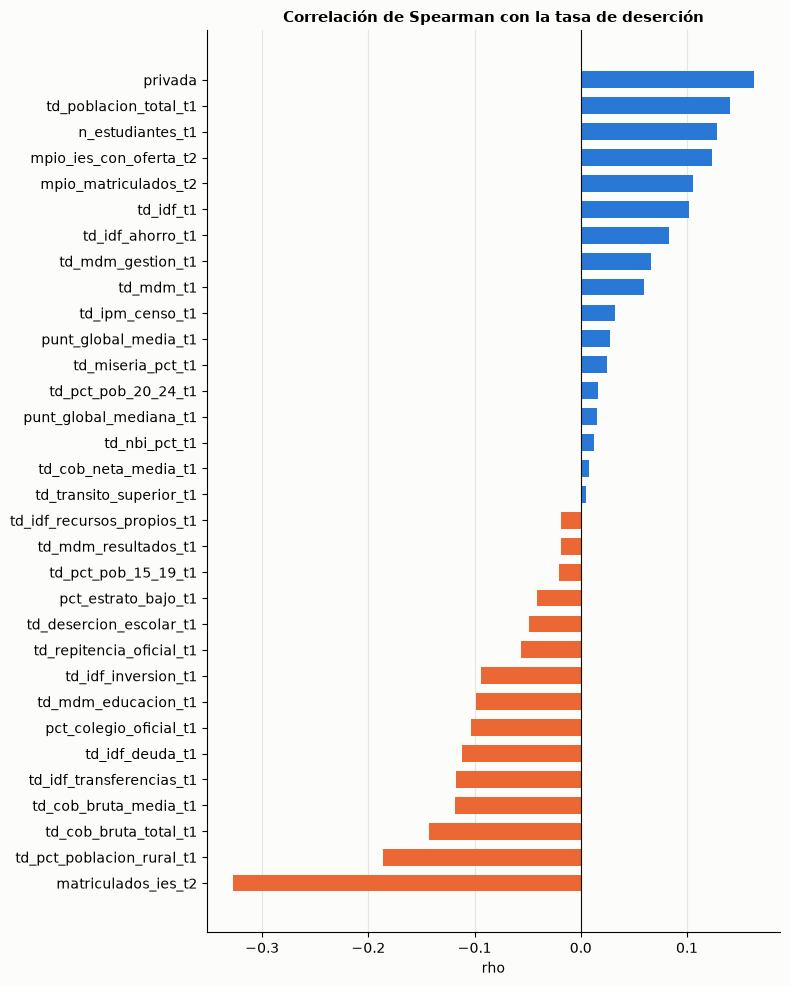

In [14]:
excluir = {"tasa_desercion", "anio"}
numericas = [c for c in df.select_dtypes("number").columns if c not in excluir]
X = df[numericas].copy()
X["privada"] = (df["naturaleza"] == "Privada").astype(int)

# Spearman: resistente a los valores atípicos de la tasa y a las relaciones no lineales monótonas
corr = X.corrwith(df["tasa_desercion"], method="spearman").dropna().sort_values()
display(corr.round(3).to_frame("rho de Spearman").T)

fig, ax = plt.subplots(figsize=(8, 0.28 * len(corr) + 1))
ax.barh(corr.index, corr.values, color=[AZUL if v >= 0 else NARANJA for v in corr.values], height=0.65)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set(title="Correlación de Spearman con la tasa de deserción", xlabel="rho")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

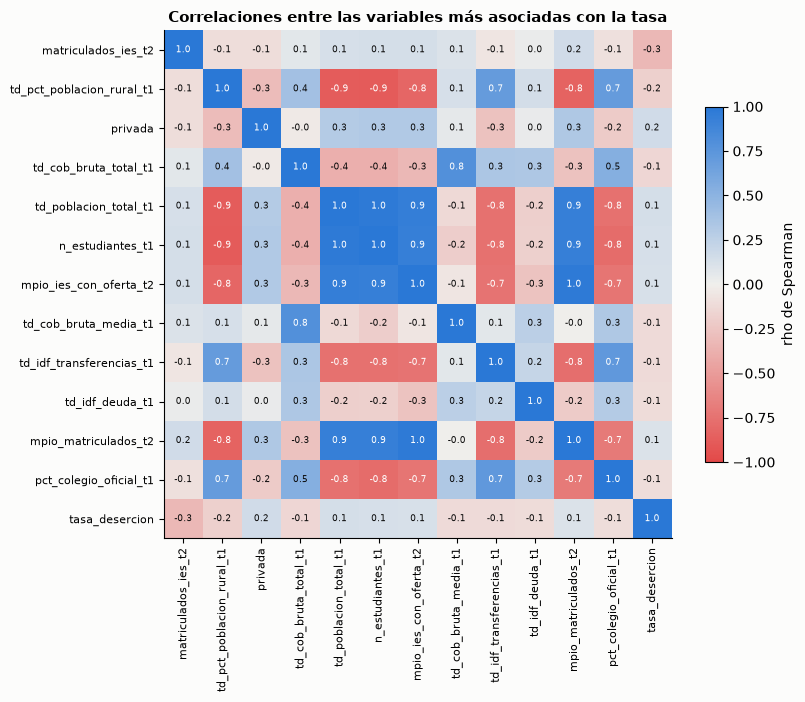

In [15]:
# Las 12 variables más asociadas con la tasa y su correlación entre sí (para detectar redundancia)
top = corr.abs().sort_values(ascending=False).head(12).index.tolist()
mat = X[top + ["privada"] if "privada" not in top else top].assign(tasa_desercion=df["tasa_desercion"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
mapa = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
im = ax.imshow(mat.values, cmap=mapa, vmin=-1, vmax=1)
ax.set_xticks(range(len(mat)), mat.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(mat)), mat.index, fontsize=8)
for i in range(len(mat)):
    for j in range(len(mat)):
        ax.text(j, i, f"{mat.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="#0b0b0b" if abs(mat.values[i, j]) < 0.6 else "#ffffff")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="rho de Spearman")
ax.set_title("Correlaciones entre las variables más asociadas con la tasa")
plt.tight_layout()
plt.show()

**Precauciones.** `matriculados_ies_t2` casi coincide con el denominador de la tasa, de modo que su asociación es en parte
mecánica. Varias variables territoriales (TerriData) son muy parecidas entre sí; antes de modelar conviene
reducirlas o regularizarlas. Las IES con sede en una misma ciudad comparten todo su contexto territorial.

## 8. Mapa por departamento

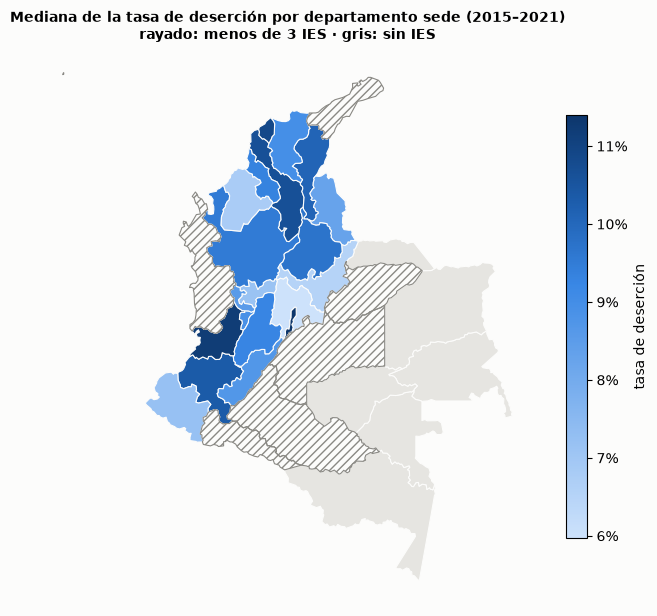

,departamento,mediana,IES
0,La Guajira,0.228,2
1,"Archipielago De San Andres, Providencia Y Sant...",0.214,1
2,Casanare,0.115,1
3,"Bogota, D.C.",0.114,100
4,Valle Del Cauca,0.112,31
5,Atlantico,0.109,17
6,Bolivar,0.106,13
7,Putumayo,0.105,1
8,Cauca,0.104,6
9,Cesar,0.101,3


Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.


In [16]:
# Polígonos departamentales del DANE (MGN 2018), guardados en data/external; se dibujan con matplotlib sin geopandas
geo = json.loads((ROOT / "data" / "external" / "departamentos_colombia.geojson").read_text(encoding="utf-8"))
valor_todos = df.groupby("cod_depto")["tasa_desercion"].median()
n_ies = df.groupby("cod_depto")["cod_ies"].nunique()
# Con 1 o 2 IES la mediana departamental no es representativa: se pintan aparte y no fijan la escala de color
valor = valor_todos[n_ies.reindex(valor_todos.index) >= 3]

norma = Normalize(vmin=valor.min(), vmax=valor.max())
cmap = LinearSegmentedColormap.from_list("rampa", RAMPA)
parches, colores, pocas = [], [], []
for f in geo["features"]:
    cod = f["properties"]["DPTO_CCDGO"]
    anillo = np.array(f["geometry"]["coordinates"][0])
    parches.append(Polygon(anillo, closed=True))
    if cod in valor.index:
        colores.append(cmap(norma(valor[cod])))
    else:
        colores.append("#fcfcfb" if cod in valor_todos.index else "#e6e5e1")
    pocas.append(cod in valor_todos.index and cod not in valor.index)

fig, ax = plt.subplots(figsize=(6.5, 8))
ax.add_collection(PatchCollection(parches, facecolor=colores, edgecolor="#fcfcfb", linewidth=0.8))
# trama diagonal sobre los departamentos con menos de 3 IES
ax.add_collection(PatchCollection([p for p, m in zip(parches, pocas) if m], facecolor="none", edgecolor=GRIS,
                                  hatch="////", linewidth=0.8))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Mediana de la tasa de deserción por departamento sede (2015–2021)\nrayado: menos de 3 IES · gris: sin IES", fontsize=10)
barra = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=cmap), ax=ax, shrink=0.55, label="tasa de deserción")
barra.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

mapa_tabla = pd.DataFrame({"departamento": valor_todos.index.map(deptos), "mediana": valor_todos.values,
                           "IES": n_ies.reindex(valor_todos.index).values})
display(mapa_tabla.sort_values("mediana", ascending=False).round(3).reset_index(drop=True))
print("Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.")

## Conclusiones

- **Distribución.** El dataset final tiene 2.042 IES-año de 311 IES. La tasa anual de deserción tiene mediana 9,8 %, media 12,2 % y, entre los percentiles 5 y 95, un rango de 4,0 % a 27,5 %. Sigue siendo muy asimétrica (3,8).
- **Efecto del denominador mínimo.** `min_matriculados_t2 = 100` elimina 97 IES-año (4,5 % de 2.148) y deja a 9 IES sin ninguna fila. Las filas eliminadas tenían mediana 24,8 % y media 27,9 %: eran sobre todo tasas inestables de instituciones chicas. La mediana global casi no cambia (10,0 % → 9,8 %), la media baja de 12,9 % a 12,2 % y el percentil 95 de 31,1 % a 27,7 %. El filtro quita 13 de las 33 filas con tasa > 50 %, pero quedan 20.
- **Tasas > 50 % que quedan y posible cierre.** Las 20 filas son de 13 IES y ninguna cae en la ventana de posible cierre (los 2 semestres previos al último reporte de una IES que dejó de reportar): 10 de las 13 IES siguen reportando en 2024-2 y las otras 3 dejaron de reportar en 2022-2, lejos de los años con tasa alta. El posible cierre no explica estas tasas; es un problema de base chica o de comportamiento estructural (por ejemplo, la IES 9903 tiene tasas de 63 % a 99 % en cinco años distintos). Por separado, `excluir_posible_cierre` (por defecto activo) saca 9 IES-año de 6 IES, una de las cuales (3116) queda sin filas. La lista completa está en `reports/tasas_altas.csv`.
- **Evolución.** La mediana baja de 10,3 % en 2015 a 9,0 % en 2021 y la media de 13,2 % a 11,1 %, con un máximo en 2017 (11,1 % de mediana). No se ve un salto en 2020; con siete años y un denominador rezagado no conviene leerlo como efecto de la pandemia.
- **Oficial y privada.** Las privadas (217 IES) tienen mediana 10,3 % y media 12,8 %; las oficiales (94 IES), 8,5 % y 10,7 %. La diferencia se mantiene en el tiempo (gráfico de líneas), pero las filas de una misma IES no son independientes, así que el valor p de Mann-Whitney solo es orientativo.
- **Departamentos.** Entre los 20 departamentos con 3 o más IES, Bogotá (11,4 %), Valle del Cauca (11,2 %), Atlántico (10,9 %) y Bolívar (10,6 %) tienen las medianas más altas; Cundinamarca (6,0 %), Boyacá (6,5 %) y Córdoba (6,8 %), las más bajas. Esas diferencias mezclan efecto territorial con composición (peso de privadas, tamaño de las IES). Los 7 departamentos con 1 o 2 IES describen solo a esas instituciones (el mapa los marca aparte).
- **Nulos.** Saber 11 tiene 28,5 % de nulos (años excluidos por cobertura incompleta del calendario A), la matrícula de SNIES hasta 29,5 % (`matriculados_ies_t2` en 2015–2016) y TerriData 5,8 % en promedio (máximo 28,6 % en el desempeño municipal, que empieza en 2016). La población de 2015–2017 ya viene de la proyección con base en el censo 2005 y no tiene nulos relevantes. Se descartaron 5 variables de TerriData por más de 50 % de nulos: cobertura en educación superior y todo el bloque de mercado laboral. **Limitación:** el modelado no podrá usar variables de mercado laboral municipal.
- **Correlaciones.** Ninguna variable explica mucho por sí sola (|rho| ≤ 0,33). La más fuerte es negativa: `matriculados_ies_t2` (-0,33); IES más grandes, menor tasa, en parte por construcción, porque es casi el denominador. Le siguen el porcentaje de población rural (-0,19), la cobertura bruta (-0,14) y, con signo positivo, ser privada (+0,16), la población (+0,14), los estudiantes de Saber 11 (+0,13) y el número de IES del municipio (+0,12). Las variables territoriales son muy colineales entre sí (población, matrícula municipal y estudiantes de Saber 11 con rho cercana a 1), de modo que habrá que reducirlas o regularizarlas.
- **Para el modelo.** La partición queda preparada en `src/modelado/particion.py` (GroupKFold por IES y partición temporal 2015–2019 / 2020–2021) y el objetivo puede transformarse con logit (`config.yaml: modelado.transformacion_objetivo`, `src/modelado/objetivo.py`), útil por la asimetría de la tasa. Pendientes: tratamiento de las tasas atípicas, colinealidad territorial y el solapamiento entre `matriculados_ies_t2` y el denominador de la tasa.